In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("ai_usage.csv")

In [3]:
df = pd.DataFrame(data)

In [4]:
df.shape

(300, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 13  Productivity_Score  

In [6]:
df.isna().sum()

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Profession                     15
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                18
Monthly_AI_Cost                12
Productivity_Score             16
Accuracy_Rating                15
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64

In [7]:
df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [8]:
# data cleaning
df["Age"] = df["Age"].str.replace(" yrs", "")

In [9]:
df["Age"] = df["Age"].astype(float)

In [10]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [11]:
df["Age"] = df["Age"].astype(int)

In [12]:
df["Gender"] = df["Gender"].fillna("Not disclosed")

In [13]:
df["Country"] = df["Country"].fillna("Others")

In [14]:
df["Education_Level"] = df["Education_Level"].fillna("Unknown")

In [15]:
df["Profession"] = df["Profession"].fillna("Unknown")

In [16]:
df["Profession"] = df["Profession"].str.replace("Unknown", "Others")

In [17]:
df["Monthly_Income"] = df["Monthly_Income"].str.replace("$", "")

In [18]:
df["Monthly_Income"] = df["Monthly_Income"].str.replace(",", "")

In [19]:
df["Monthly_Income"] = df["Monthly_Income"].astype(float)

In [20]:
df["Monthly_Income"] = df["Monthly_Income"].fillna(df["Monthly_Income"].mean())

In [21]:
df["AI_Tool"] = df["AI_Tool"].fillna("Others")

In [22]:
df["AI_Purpose"] = df["AI_Purpose"].fillna("Others")

In [23]:
df["AI_Usage_Hours_Per_Day"] = df["AI_Usage_Hours_Per_Day"].str.replace(" hrs", "")

In [24]:
df["AI_Usage_Hours_Per_Day"] = df["AI_Usage_Hours_Per_Day"].astype(float)

In [25]:
data = df["AI_Usage_Hours_Per_Day"].mean()
df["AI_Usage_Hours_Per_Day"] = df["AI_Usage_Hours_Per_Day"].fillna(data)

In [26]:
df["Tasks_Performed"] = df["Tasks_Performed"].fillna("Others")

In [27]:
df["Monthly_AI_Cost"] = df["Monthly_AI_Cost"].str.replace("$", "")

In [28]:
df["Monthly_AI_Cost"] = df["Monthly_AI_Cost"].astype(float)

In [29]:
cost = df["Monthly_AI_Cost"].mean()
df["Monthly_AI_Cost"] = df["Monthly_AI_Cost"].fillna(cost)

In [30]:
df["Time_Saved_Hours_Per_Week"] = df["Time_Saved_Hours_Per_Week"].str.replace(" hrs", "")

In [31]:
df["Time_Saved_Hours_Per_Week"] = df["Time_Saved_Hours_Per_Week"].astype(float)

In [32]:
df["Work_or_Study_Hours_Per_Day"] = df["Work_or_Study_Hours_Per_Day"].str.replace(" hrs", "")

In [33]:
df["Work_or_Study_Hours_Per_Day"] = df["Work_or_Study_Hours_Per_Day"].astype(float)

In [34]:
cols_list = ["Productivity_Score", "Accuracy_Rating", "Satisfaction_Score", "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]
for title in cols_list:
    df[title] = df[title].fillna(df[title].mean())

In [35]:
df["Would_Recommend"] = df["Would_Recommend"].fillna("Maybe")

In [36]:
df.isna().sum()

User_ID                        0
Age                            0
Gender                         0
Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 0
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Tasks_Performed                0
Monthly_AI_Cost                0
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             0
Time_Saved_Hours_Per_Week      0
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64

In [48]:
df["AI_Usage_Hours_Per_Day"].max()

23.0

In [49]:
df = df[df["AI_Usage_Hours_Per_Day"] != 23]

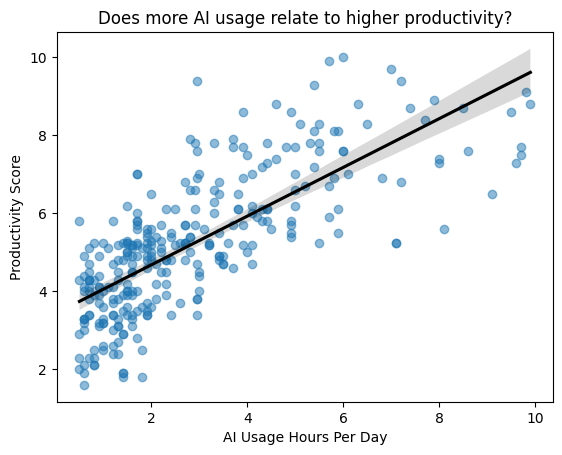

Correlation: 0.75


In [60]:
# AI usage and productivity
x = df["AI_Usage_Hours_Per_Day"]
y = df["Productivity_Score"]

plt.scatter(x, y, alpha = 0.5, label = "Data points")
sns.regplot(x=x, y=y, scatter = False, color = "black")

plt.xlabel("AI Usage Hours Per Day")
plt.ylabel("Productivity Score")
plt.title("Does more AI usage relate to higher productivity?")
plt.show()

print("Correlation:", x.corr(y).round(2))

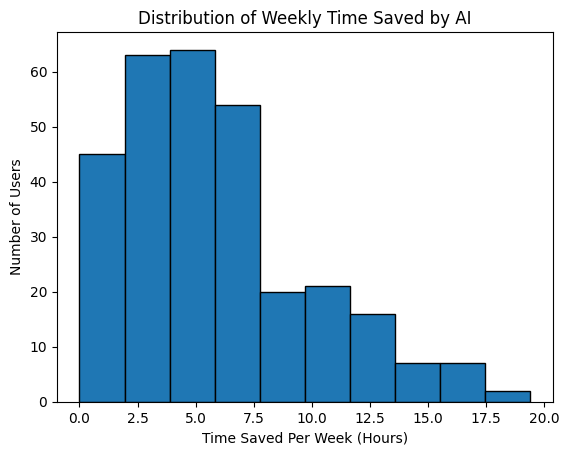

In [69]:
# time AI savess
plt.hist(df["Time_Saved_Hours_Per_Week"], bins=10, edgecolor="black")

plt.xlabel("Time Saved Per Week (Hours)")
plt.ylabel("Number of Users")
plt.title("Distribution of Weekly Time Saved by AI")

plt.show()

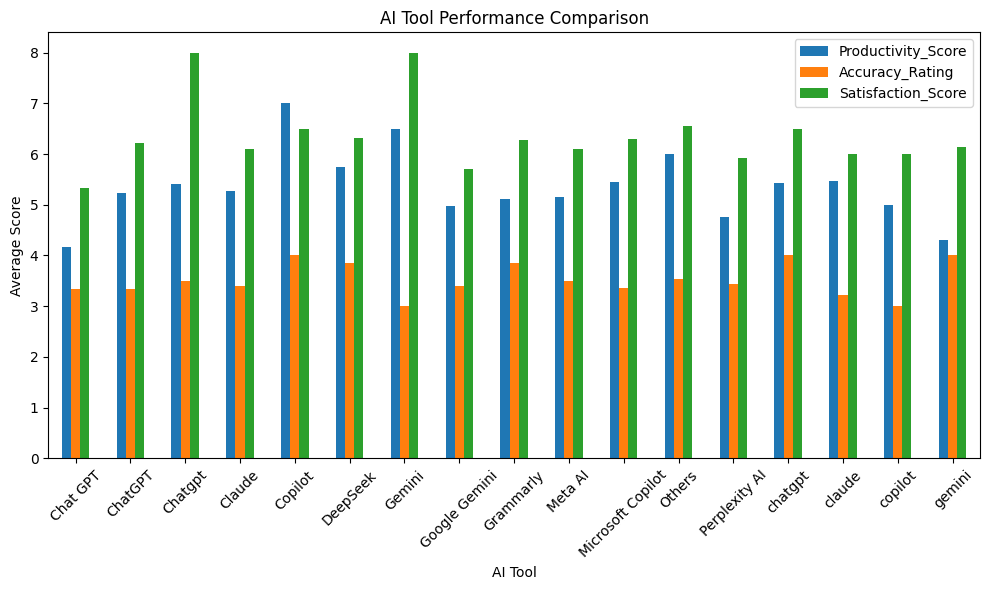

In [67]:
# best AI tool
tool_performance = df.groupby("AI_Tool")[
    ["Productivity_Score", "Accuracy_Rating", "Satisfaction_Score"]
].mean()

tool_performance.plot(kind="bar", figsize=(10, 6))

plt.title("AI Tool Performance Comparison")
plt.xlabel("AI Tool")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

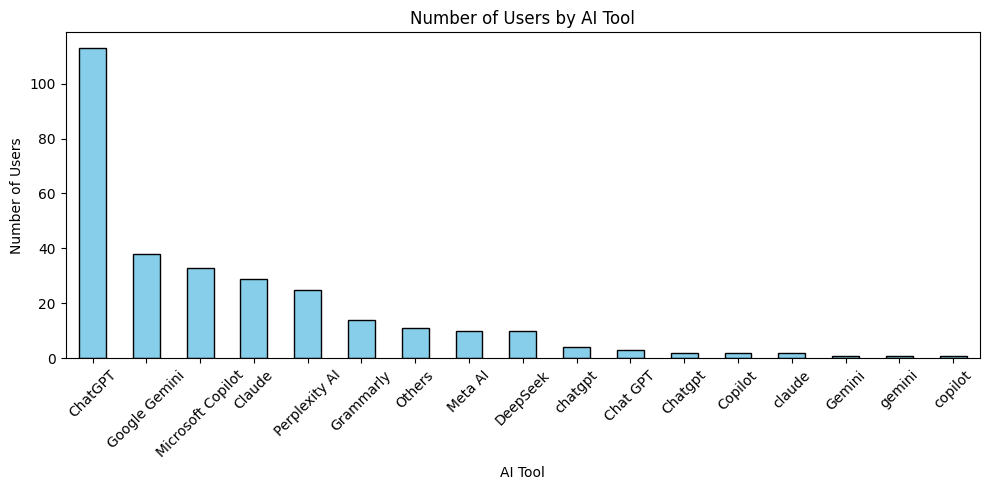

In [70]:
# Number of users based on AI tools
df["AI_Tool"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Number of Users by AI Tool")
plt.xlabel("AI Tool")
plt.ylabel("Number of Users")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

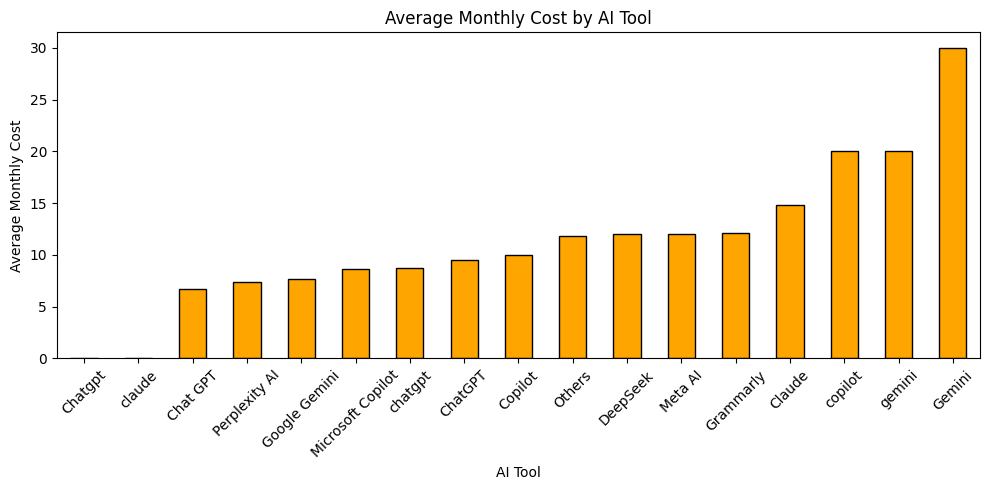

In [72]:
# monthly AI costs
monthly_cost = df.groupby("AI_Tool")["Monthly_AI_Cost"].mean().sort_values()

monthly_cost.plot(
    kind="bar",
    figsize=(10, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Average Monthly Cost by AI Tool")
plt.xlabel("AI Tool")
plt.ylabel("Average Monthly Cost")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

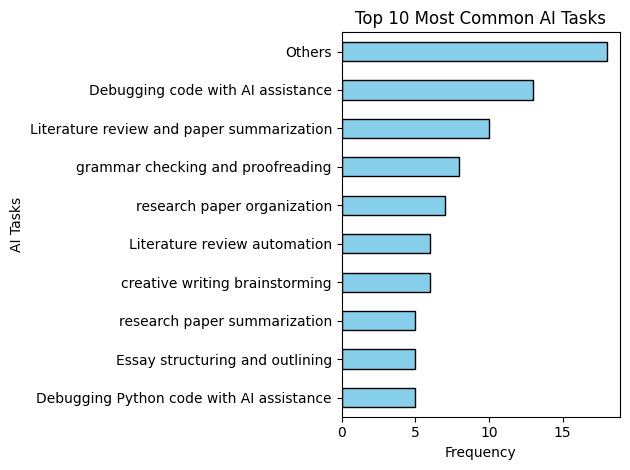

In [75]:
# application of AI

# Spliting tasks and counting each individual task
tasks = df["Tasks_Performed"].str.split(",").explode().str.strip()

# Plotting the 10 most common tasks
tasks.value_counts().head(10).sort_values().plot(
    kind="barh",
    color="skyblue",
    edgecolor="black"
)

plt.title("Top 10 Most Common AI Tasks")
plt.xlabel("Frequency")
plt.ylabel("AI Tasks")
plt.tight_layout()
plt.show()

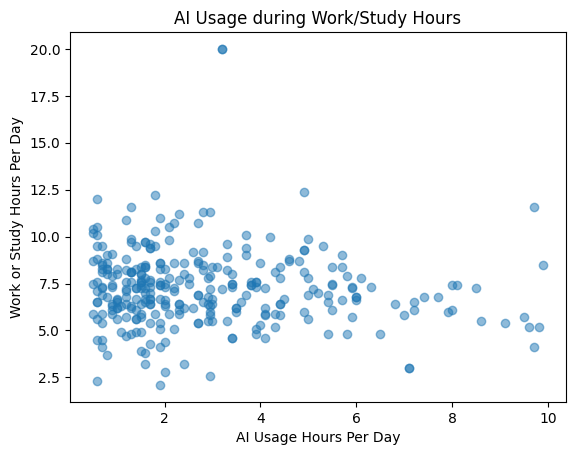

Correlation: -0.088


In [87]:
# ai usage in work/study hours
x = df["AI_Usage_Hours_Per_Day"]
y = df["Work_or_Study_Hours_Per_Day"]

plt.scatter(x, y, alpha=0.5)

plt.xlabel("AI Usage Hours Per Day")
plt.ylabel("Work or Study Hours Per Day")
plt.title("AI Usage during Work/Study Hours")
plt.show()

print("Correlation:", x.corr(y).round(3))

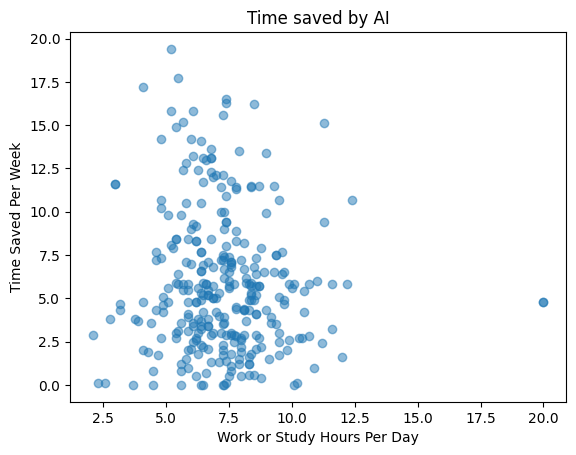

Correlation: -0.072


In [90]:
# Time saved in work/study hours by AI
x = df["Work_or_Study_Hours_Per_Day"]
y = df["Time_Saved_Hours_Per_Week"]

plt.scatter(x, y, alpha=0.5)

plt.xlabel("Work or Study Hours Per Day")
plt.ylabel("Time Saved Per Week")
plt.title("Time saved by AI")
plt.show()

print("Correlation:", x.corr(y).round(3))

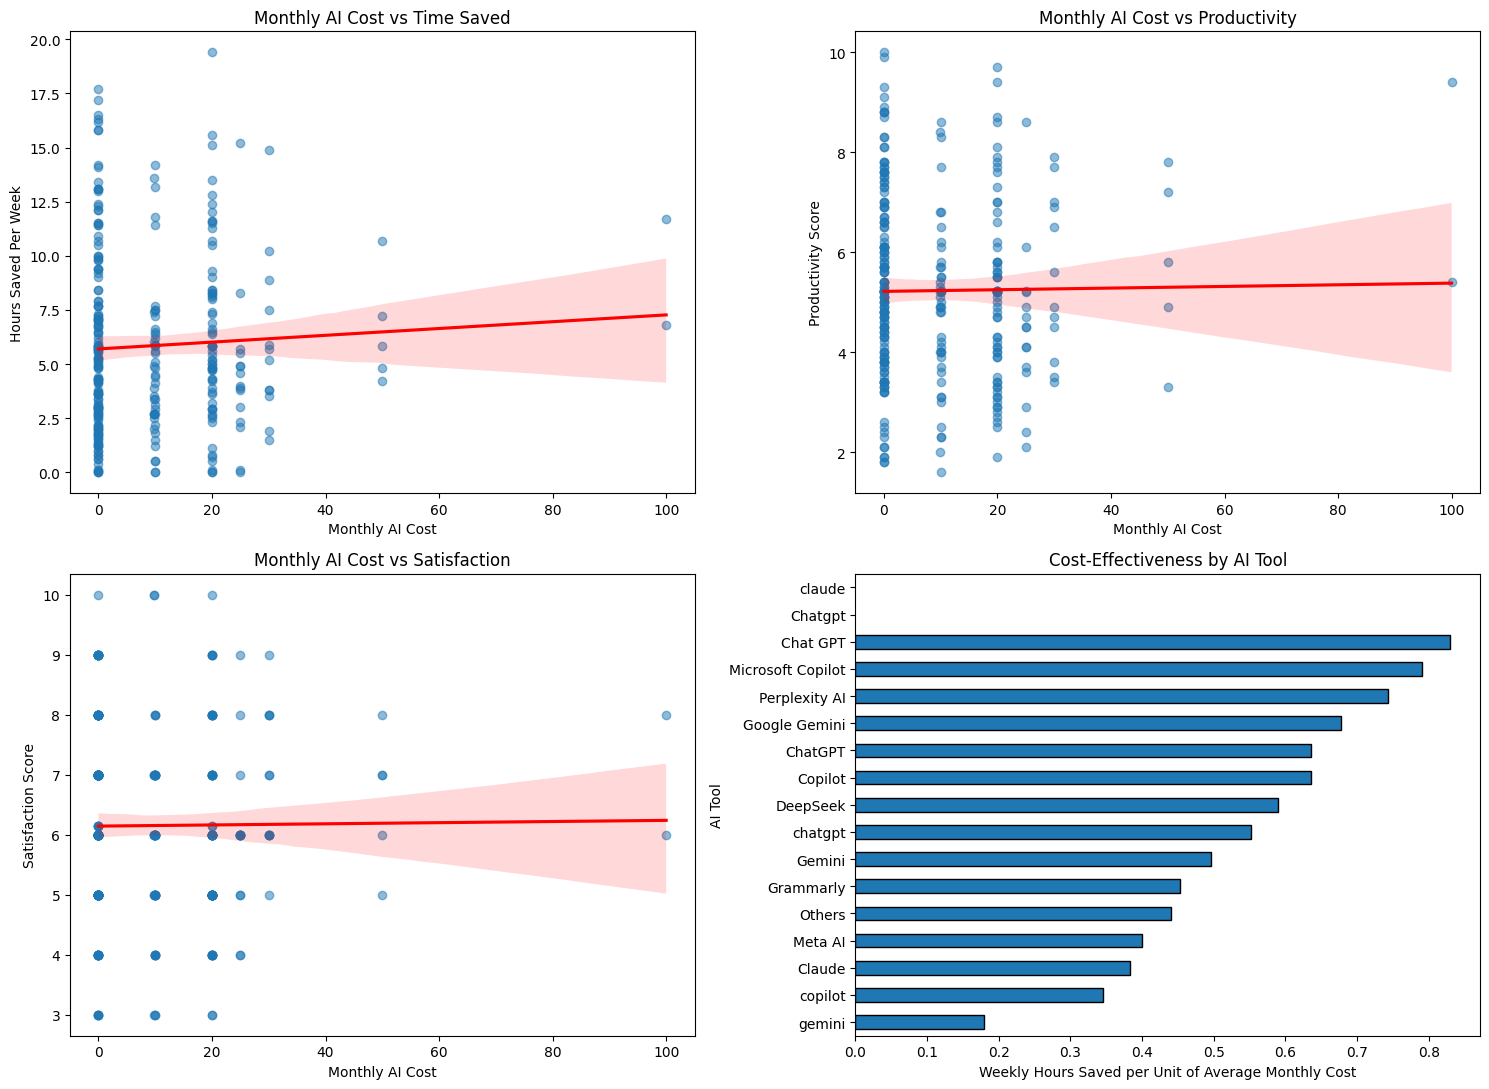

Cost vs time saved: 0.0526
Cost vs productivity: 0.0126
Cost vs satisfaction: 0.0086

AI tool cost-benefit comparison:
                   Average_Cost  Average_Time_Saved  Hours_Saved_Per_Cost_Unit
AI_Tool                                                                       
Chatgpt                    0.00                4.80                        inf
claude                     0.00                5.00                        inf
Chat GPT                   6.67                5.53                       0.83
Microsoft Copilot          8.64                6.83                       0.79
Perplexity AI              7.40                5.49                       0.74
Google Gemini              7.63                5.17                       0.68
ChatGPT                    9.46                6.02                       0.64
Copilot                   10.00                6.35                       0.64
DeepSeek                  12.00                7.07                       0.59
chatgpt     

In [97]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Monthly AI cost vs time saved
sns.regplot(
    data=df,
    x="Monthly_AI_Cost",
    y="Time_Saved_Hours_Per_Week",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly AI Cost vs Time Saved")
axes[0, 0].set_xlabel("Monthly AI Cost")
axes[0, 0].set_ylabel("Hours Saved Per Week")

# 2. Monthly AI cost vs productivity
sns.regplot(
    data=df,
    x="Monthly_AI_Cost",
    y="Productivity_Score",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[0, 1]
)
axes[0, 1].set_title("Monthly AI Cost vs Productivity")
axes[0, 1].set_xlabel("Monthly AI Cost")
axes[0, 1].set_ylabel("Productivity Score")

# 3. Monthly AI cost vs satisfaction
sns.regplot(
    data=df,
    x="Monthly_AI_Cost",
    y="Satisfaction_Score",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly AI Cost vs Satisfaction")
axes[1, 0].set_xlabel("Monthly AI Cost")
axes[1, 0].set_ylabel("Satisfaction Score")

# 4. Cost-effectiveness by AI tool
tool_data = df.groupby("AI_Tool").agg(
    Average_Cost=("Monthly_AI_Cost", "mean"),
    Average_Time_Saved=("Time_Saved_Hours_Per_Week", "mean")
)

tool_data["Hours_Saved_Per_Cost_Unit"] = (
    tool_data["Average_Time_Saved"] /
    tool_data["Average_Cost"]
)

tool_data["Hours_Saved_Per_Cost_Unit"].sort_values().plot(
    kind="barh",
    ax=axes[1, 1],
    edgecolor="black"
)

axes[1, 1].set_title("Cost-Effectiveness by AI Tool")
axes[1, 1].set_xlabel("Weekly Hours Saved per Unit of Average Monthly Cost")
axes[1, 1].set_ylabel("AI Tool")

plt.tight_layout()
plt.show()

# Printing correlations
print("Cost vs time saved:",
      df["Monthly_AI_Cost"].corr(df["Time_Saved_Hours_Per_Week"]).round(4))

print("Cost vs productivity:",
      df["Monthly_AI_Cost"].corr(df["Productivity_Score"]).round(4))

print("Cost vs satisfaction:",
      df["Monthly_AI_Cost"].corr(df["Satisfaction_Score"]).round(4))

# Display tool comparison
print("\nAI tool cost-benefit comparison:")
print(tool_data.sort_values("Hours_Saved_Per_Cost_Unit", ascending=False).round(2))


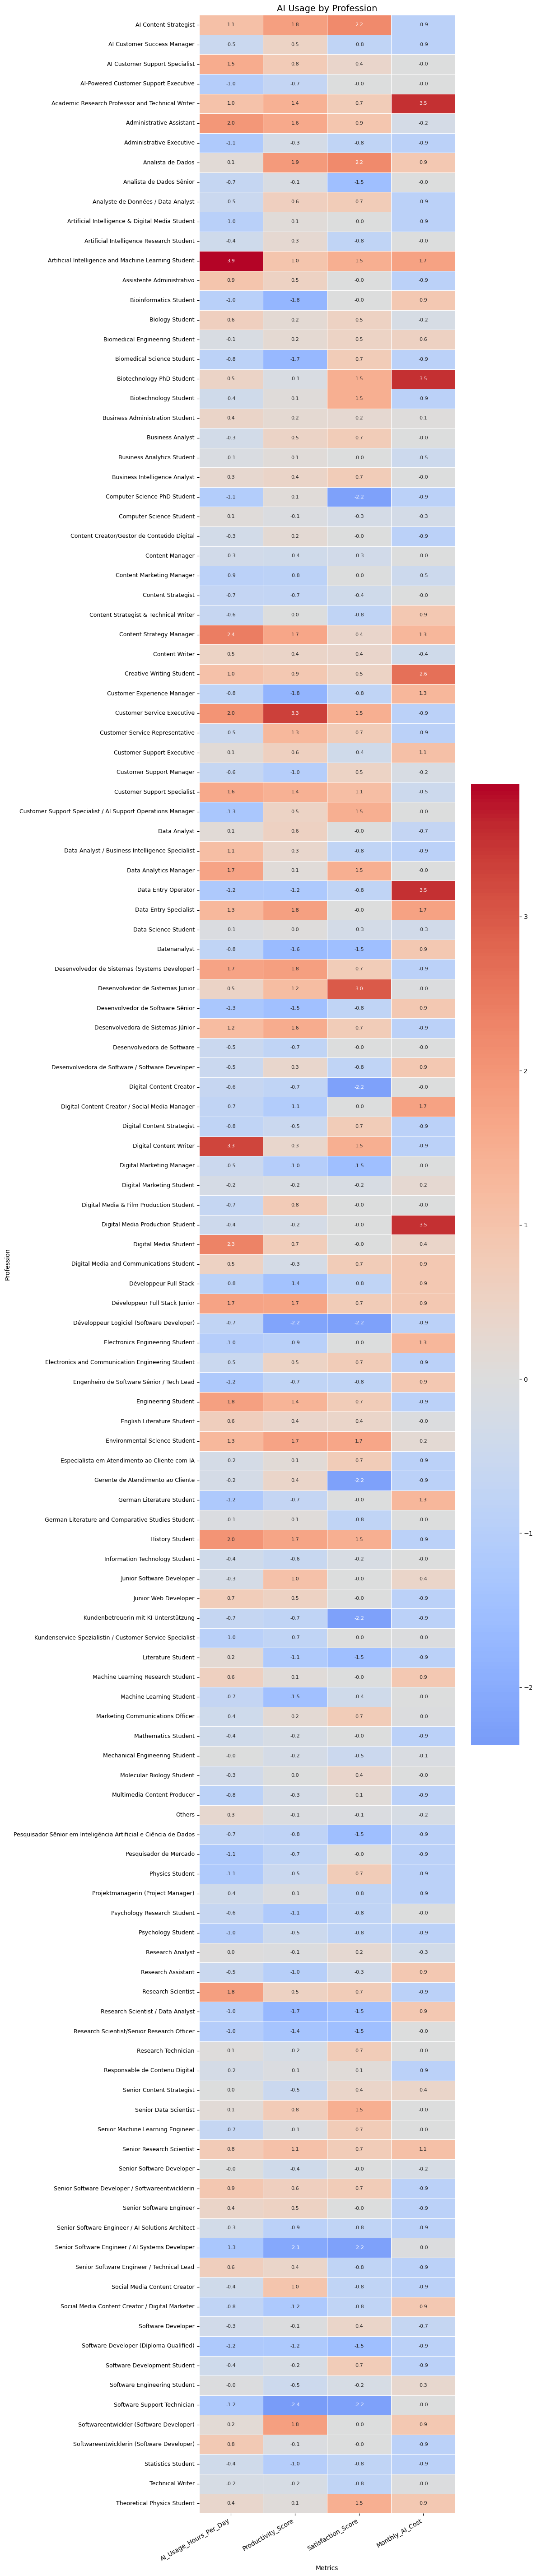

In [99]:
# difference of AI usage
metrics = [
    "AI_Usage_Hours_Per_Day",
    "Productivity_Score",
    "Satisfaction_Score",
    "Monthly_AI_Cost"
]

# Group by profession
summary = df.groupby("Profession")[metrics].mean()

scaled = (summary - summary.mean()) / summary.std()
scaled = scaled.fillna(0)

plt.figure(figsize=(12, max(6, len(scaled) * 0.45)))

sns.heatmap(
    scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".1f",
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title("AI Usage by Profession", fontsize=14)
plt.xlabel("Metrics")
plt.ylabel("Profession")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

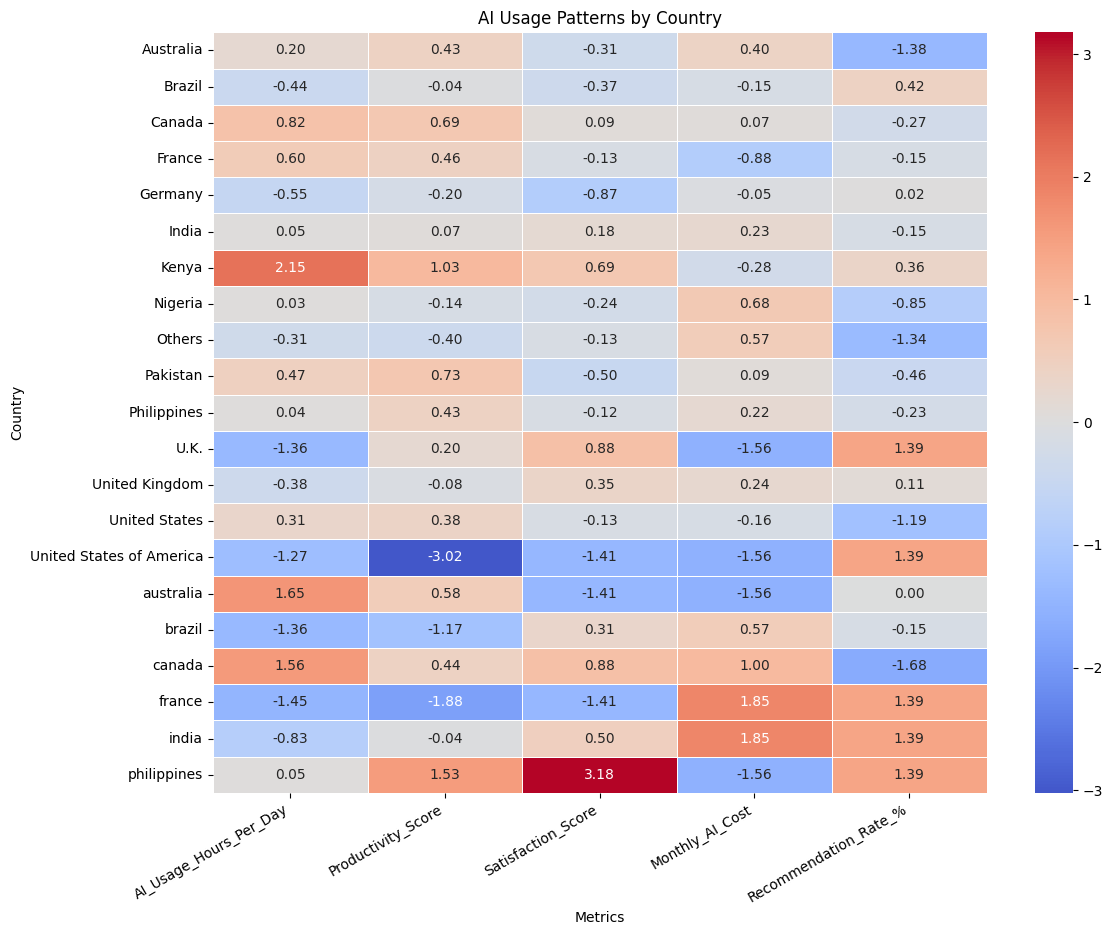

In [101]:
# usage patterns by country
metrics = [
    "AI_Usage_Hours_Per_Day",
    "Productivity_Score",
    "Satisfaction_Score",
    "Monthly_AI_Cost"
]


country_summary = df.groupby("Country")[metrics].mean()


recommendation_rate = (
    df["Would_Recommend"]
    .astype(str).str.strip().str.lower()
    .map({"yes": 1, "no": 0})
    .groupby(df["Country"])
    .mean() * 100
)

country_summary["Recommendation_Rate_%"] = recommendation_rate


scaled = (
    country_summary - country_summary.mean()
) / country_summary.std()

scaled = scaled.fillna(0)

# Plotting heatmap
plt.figure(figsize=(12, max(6, len(scaled) * 0.45)))

sns.heatmap(
    scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("AI Usage Patterns by Country")
plt.xlabel("Metrics")
plt.ylabel("Country")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


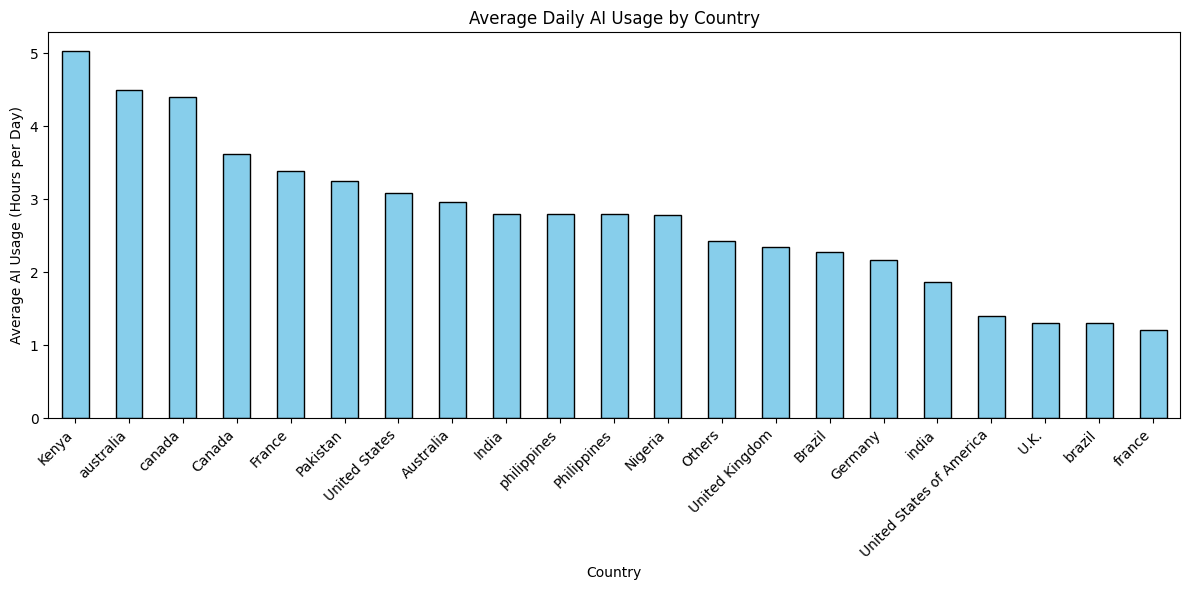

In [103]:
# country that uses ai

country_usage = (
    df.groupby("Country")["AI_Usage_Hours_Per_Day"]
    .mean()
    .sort_values(ascending=False)
)

country_usage.plot(
    kind="bar",
    figsize=(12, 6),
    color="skyblue",
    edgecolor="black"
)

plt.title("Average Daily AI Usage by Country")
plt.xlabel("Country")
plt.ylabel("Average AI Usage (Hours per Day)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


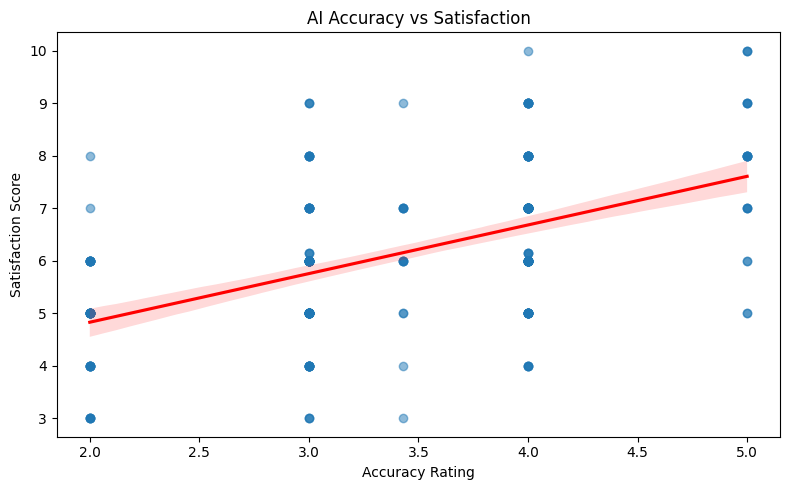

Correlation: 0.516


In [104]:
#comparing accuracy rating with satisfaction score
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="Accuracy_Rating",
    y="Satisfaction_Score",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("AI Accuracy vs Satisfaction")
plt.xlabel("Accuracy Rating")
plt.ylabel("Satisfaction Score")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    df["Accuracy_Rating"].corr(df["Satisfaction_Score"]).round(3)
)


In [106]:
# Group data by AI tool
tool_value = (
    df.groupby("AI_Tool")
    .agg(
        Users=("User_ID", "nunique"),
        Avg_Monthly_Cost=("Monthly_AI_Cost", "mean"),
        Avg_Productivity=("Productivity_Score", "mean"),
        Avg_Weekly_Time_Saved=("Time_Saved_Hours_Per_Week", "mean")
    )
    .reset_index()
)

# Estimate monthly time saved
tool_value["Monthly_Hours_Saved"] = (
    tool_value["Avg_Weekly_Time_Saved"] * 4.33
)

# Calculate cost per reported hour saved
tool_value["Cost_Per_Hour_Saved"] = np.where(
    tool_value["Monthly_Hours_Saved"] > 0,
    tool_value["Avg_Monthly_Cost"] /
    tool_value["Monthly_Hours_Saved"],
    np.nan
)

# Display results
tool_value = tool_value.sort_values(
    "Cost_Per_Hour_Saved",
    ascending=True,
    na_position="last"
)

print(tool_value.round(2).to_string(index=False))

          AI_Tool  Users  Avg_Monthly_Cost  Avg_Productivity  Avg_Weekly_Time_Saved  Monthly_Hours_Saved  Cost_Per_Hour_Saved
          Chatgpt      2              0.00              5.40                   4.80                20.78                 0.00
           claude      2              0.00              5.47                   5.00                21.65                 0.00
         Chat GPT      3              6.67              4.17                   5.53                23.96                 0.28
Microsoft Copilot     30              8.64              5.45                   6.83                29.57                 0.29
    Perplexity AI     23              7.40              4.76                   5.49                23.79                 0.31
    Google Gemini     36              7.63              4.99                   5.17                22.38                 0.34
          ChatGPT    110              9.46              5.24                   6.02                26.05              

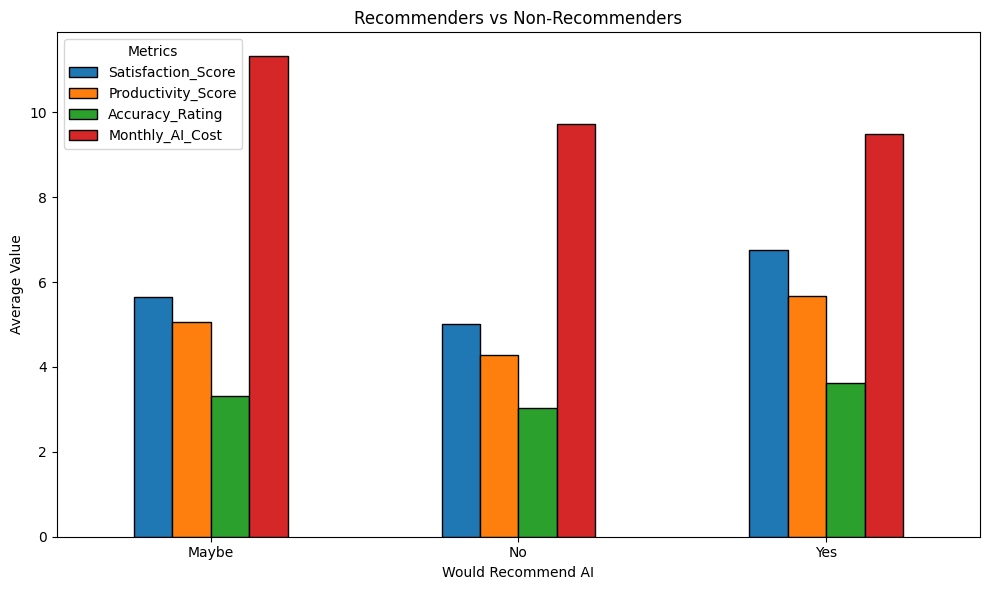

                 Satisfaction_Score  Productivity_Score  Accuracy_Rating  \
Would_Recommend                                                            
Maybe                          5.66                5.05             3.32   
No                             5.01                4.27             3.04   
Yes                            6.75                5.67             3.62   

                 Monthly_AI_Cost  
Would_Recommend                   
Maybe                      11.32  
No                          9.71  
Yes                         9.49  


In [107]:
metrics = [
    "Satisfaction_Score",
    "Productivity_Score",
    "Accuracy_Rating",
    "Monthly_AI_Cost"
]


summary = df.groupby("Would_Recommend")[metrics].mean()

summary.plot(kind="bar", figsize=(10, 6), edgecolor="black")

plt.title("Recommenders vs Non-Recommenders")
plt.xlabel("Would Recommend AI")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

print(summary.round(2))


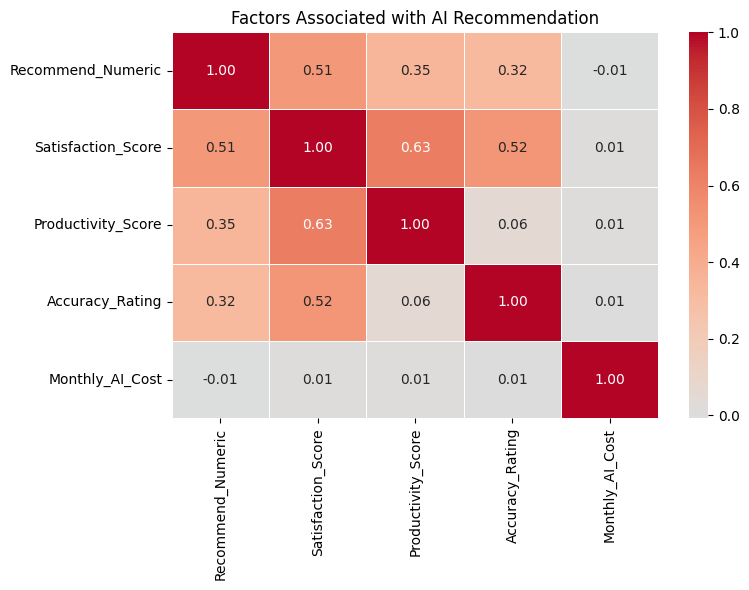

In [108]:
df["Recommend_Numeric"] = (
    df["Would_Recommend"]
    .astype(str).str.strip().str.lower()
    .map({"yes": 1, "no": 0})
)

corr = df[
    [
        "Recommend_Numeric",
        "Satisfaction_Score",
        "Productivity_Score",
        "Accuracy_Rating",
        "Monthly_AI_Cost"
    ]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Factors Associated with AI Recommendation")
plt.tight_layout()
plt.show()
